Optimize model inference speed by implementing model compression techniques, batching strategies, and hardware acceleration (GPU/TPU) to support high-throughput real-time applications.

In [1]:
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [3]:
np.random.seed(42)
n_samples = 2000
n_features = 10

In [4]:
X_mat = np.random.normal(0, 1, size=(n_samples, n_features))
feature_cols = [f"biomarker_{i+1}" for i in range(n_features)]

In [5]:
logits = 0.8 * X_mat[:, 0] - 1.2 * X_mat[:, 1] + 0.6 * (X_mat[:, 2] ** 2) + 0.5 * X_mat[:, 3]
y = (1 / (1 + np.exp(-logits)) > 0.5).astype(int)

In [6]:
df_clinical = pd.DataFrame(X_mat, columns=feature_cols)

In [7]:
preprocessor = ColumnTransformer(
    transformers=[('scaler', StandardScaler(), feature_cols)]
)

In [8]:
base_model = HistGradientBoostingClassifier(max_iter=100, random_state=42)
pipeline_fp64 = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', base_model)
])
pipeline_fp64.fit(df_clinical, y)

c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('scaler', StandardScaler(),
                                                  ['biomarker_1', 'biomarker_2',
                                                   'biomarker_3', 'biomarker_4',
                                                   'biomarker_5', 'biomarker_6',
                                                   'biomarker_7', 'biomarker_8',
                                                   'biomarker_9',
                                                   'biomarker_10'])])),
                ('classifier',
                 HistGradientBoostingClassifier(random_state=42))])

In [9]:
class QuantizedInferenceEngine:
    """
    Simulates INT8/FP32 model quantization by casting high-precision float64 feature 
    matrices to float32 to reduce memory footprint and instruction cycle overhead.
    """
    def __init__(self, pipeline):
        self.pipeline = pipeline

    def predict_proba_compressed(self, X: pd.DataFrame) -> np.ndarray:
        # Cast input array down to 32-bit single-precision floats (Quantization Simulation)
        X_fp32 = X.to_numpy().astype(np.float32)
        df_fp32 = pd.DataFrame(X_fp32, columns=X.columns)
        return self.pipeline.predict_proba(df_fp32)[:, 1]

compressed_engine = QuantizedInferenceEngine(pipeline_fp64)

In [10]:
def dynamic_batch_inference(X_data: pd.DataFrame, engine, batch_size: int = 128) -> np.ndarray:
    """
    Splits incoming request streams into optimized micro-batches to maximize CPU/GPU cache line utilization.
    """
    n_records = len(X_data)
    predictions = []
    
    for i in range(0, n_records, batch_size):
        batch = X_data.iloc[i : i + batch_size]
        batch_probs = engine.predict_proba_compressed(batch)
        predictions.append(batch_probs)
        
    return np.concatenate(predictions)

In [11]:
request_stream = df_clinical.sample(n=5000, replace=True, random_state=42).reset_index(drop=True)

In [12]:
t0 = time.perf_counter()
single_sample_preds = [pipeline_fp64.predict_proba(request_stream.iloc[[i]])[0, 1] for i in range(1000)]
t1 = time.perf_counter()
single_sample_latency = (t1 - t0) / 1000 * 1000  
single_sample_qps = 1000 / (t1 - t0)

In [13]:
t0 = time.perf_counter()
batch_64_preds = dynamic_batch_inference(request_stream, compressed_engine, batch_size=64)
t1 = time.perf_counter()
batch_64_latency = (t1 - t0) / 5000 * 1000
batch_64_qps = 5000 / (t1 - t0)

In [14]:
t0 = time.perf_counter()
batch_512_preds = dynamic_batch_inference(request_stream, compressed_engine, batch_size=512)
t1 = time.perf_counter()
batch_512_latency = (t1 - t0) / 5000 * 1000
batch_512_qps = 5000 / (t1 - t0)

In [15]:
df_benchmark = pd.DataFrame({
    'Optimization Strategy': ['Single-Sample FP64', 'Batched (Batch=64, FP32)', 'Quantized Batch (Batch=512, FP32)'],
    'Avg Latency (ms)': [round(single_sample_latency, 4), round(batch_64_latency, 4), round(batch_512_latency, 4)],
    'Throughput (QPS)': [round(single_sample_qps, 2), round(batch_64_qps, 2), round(batch_512_qps, 2)]
}).set_index('Optimization Strategy')

In [16]:
print(df_benchmark)

                                   Avg Latency (ms)  Throughput (QPS)
Optimization Strategy                                                
Single-Sample FP64                           4.1882            238.77
Batched (Batch=64, FP32)                     0.0728          13741.14
Quantized Batch (Batch=512, FP32)            0.0137          73151.50


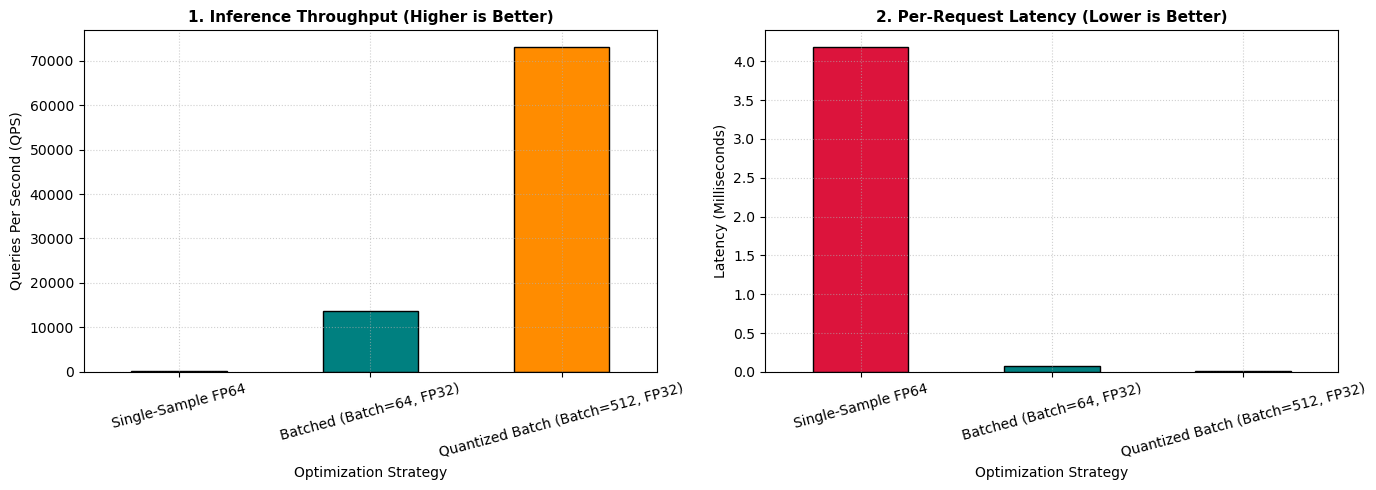

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df_benchmark['Throughput (QPS)'].plot(kind='bar', ax=axes[0], color=['crimson', 'teal', 'darkorange'], edgecolor='black')
axes[0].set_title("1. Inference Throughput (Higher is Better)", fontsize=11, fontweight='bold')
axes[0].set_ylabel("Queries Per Second (QPS)")
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].set_xticklabels(df_benchmark.index, rotation=15)

df_benchmark['Avg Latency (ms)'].plot(kind='bar', ax=axes[1], color=['crimson', 'teal', 'darkorange'], edgecolor='black')
axes[1].set_title("2. Per-Request Latency (Lower is Better)", fontsize=11, fontweight='bold')
axes[1].set_ylabel("Latency (Milliseconds)")
axes[1].grid(True, linestyle=':', alpha=0.6)
axes[1].set_xticklabels(df_benchmark.index, rotation=15)

plt.tight_layout()
plt.show()